# MDVA — Análisis de Variabilidad Espacial de Precipitación
## Justificación técnica del uso de datos locales (SIATA) vs modelo global (Open-Meteo)

**Proyecto:** Monitoreo de Variables Ambientales — UPB 2026-I  
**Autores:** Nicolás Meneses · Luis Ángel Seoanes  
**Sprint:** 2 — KR2: Definir predicción pública de referencia  

---

### Objetivo de este notebook

Demostrar cuantitativamente que Open-Meteo (modelo global ERA5/GFS, resolución ~25 km)  
**no captura la variabilidad espacial del microclima del Valle de Aburrá**.  
Esto justifica técnicamente por qué el proyecto necesita datos de la red del SIATA  
y establece a Open-Meteo como **benchmark de referencia pública** para el KR2,  
no como fuente de entrenamiento del modelo.

> ⚠️ **Advertencia:** Los datos de este notebook provienen exclusivamente de Open-Meteo.  
> Son datos de prototipo — no representan el microclima real del Valle de Aburrá.  
> Los resultados del modelo en esta fase son **indicativos**, no definitivos.

## 0. Instalación de dependencias
Ejecutar solo si es la primera vez.

In [16]:
# !pip install requests pandas numpy matplotlib seaborn scikit-learn

## 1. Configuración — Puntos del Valle de Aburrá

In [17]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, confusion_matrix
)
import warnings
warnings.filterwarnings('ignore')

# ── Paleta visual del proyecto ─────────────────────────────────────────────
COLORS = {
    'primary':   '#1F4E79',
    'secondary': '#2E75B6',
    'accent':    '#E07B00',
    'ok':        '#2E7D32',
    'warn':      '#C62828',
    'neutral':   '#666666',
}
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 13, 'axes.labelsize': 11})

# ── Puntos representativos del Valle de Aburrá ────────────────────────────
# Seleccionados para cubrir el gradiente norte-sur y la variación orográfica
PUNTOS = {
    'Barbosa (N extremo)':      {'lat': 6.4370, 'lon': -75.3317, 'color': '#1F4E79'},
    'Bello (N Valle)':          {'lat': 6.3367, 'lon': -75.5567, 'color': '#2E75B6'},
    'Robledo (NW Medellín)':    {'lat': 6.2833, 'lon': -75.6000, 'color': '#5BA3D9'},
    'Centro (La Candelaria)':   {'lat': 6.2518, 'lon': -75.5636, 'color': '#E07B00'},
    'El Poblado (SE)':          {'lat': 6.2100, 'lon': -75.5600, 'color': '#C62828'},
    'Envigado (S Valle)':       {'lat': 6.1719, 'lon': -75.5906, 'color': '#7B1FA2'},
    'Itagüí (SW)':              {'lat': 6.1847, 'lon': -75.6144, 'color': '#2E7D32'},
    'Caldas (S extremo)':       {'lat': 6.0942, 'lon': -75.6367, 'color': '#4E342E'},
}

# ── Período de análisis ───────────────────────────────────────────────────
# Un año completo para capturar ambas temporadas de lluvia de Medellín
START_DATE = '2016-01-01'
END_DATE   = '2025-12-31'

# Umbral estándar OMM para binarizar lluvia
LLUVIA_UMBRAL_MM = 0.1

print(f'Período de análisis: {START_DATE} → {END_DATE}')
print(f'Puntos de muestreo: {len(PUNTOS)}')
print(f'Umbral de lluvia: ≥ {LLUVIA_UMBRAL_MM} mm/h')

Período de análisis: 2016-01-01 → 2025-12-31
Puntos de muestreo: 8
Umbral de lluvia: ≥ 0.1 mm/h


## 2. Descarga de datos — Open-Meteo Archive API

In [18]:
import time
import os

def descargar_punto(nombre, lat, lon, start, end):
    """
    Descarga datos horarios históricos de Open-Meteo para un punto geográfico.
    Retorna un DataFrame con las variables ambientales del proyecto.
    Incluye reintentos automáticos ante rate limiting (HTTP 429).
    """
    url = 'https://archive-api.open-meteo.com/v1/archive'
    params = {
        'latitude':    lat,
        'longitude':   lon,
        'start_date':  start,
        'end_date':    end,
        'hourly': ','.join([
            'precipitation',
            'temperature_2m',
            'relative_humidity_2m',
            'cloud_cover',
            'wind_speed_10m',
            'weather_code',
        ]),
        'timezone': 'America/Bogota',
    }

    for intento in range(3):
        resp = requests.get(url, params=params, timeout=30)
        if resp.status_code == 200:
            break
        elif resp.status_code == 429:
            espera = 60 * (intento + 1)
            print(f'    Rate limit — esperando {espera}s (intento {intento + 1}/3)...')
            time.sleep(espera)
        else:
            resp.raise_for_status()

    data = resp.json()['hourly']

    df = pd.DataFrame(data)
    df['time'] = pd.to_datetime(df['time'])
    df = df.rename(columns={
        'precipitation':        'precipitacion_mm',
        'temperature_2m':       'temperatura_c',
        'relative_humidity_2m': 'humedad_relativa_pct',
        'cloud_cover':          'cobertura_nubosa_pct',
        'wind_speed_10m':       'velocidad_viento_ms',
        'weather_code':         'codigo_clima',
    })
    df['punto']        = nombre
    df['latitud']      = lat
    df['longitud']     = lon
    df['es_sintetico'] = True  # flag del esquema canónico
    df['fuente']       = 'OPEN_METEO'

    # Variable objetivo binaria
    df['llueve'] = (df['precipitacion_mm'] >= LLUVIA_UMBRAL_MM).astype(int)

    return df


# Descarga para todos los puntos con caché en CSV
os.makedirs('data', exist_ok=True)

dfs = []
for nombre, cfg in PUNTOS.items():
    nombre_archivo = nombre.replace(' ', '_').replace('(', '').replace(')', '').replace('→', '')
    ruta_csv = f'data/{nombre_archivo}.csv'

    if os.path.exists(ruta_csv):
        print(f'  Cargando desde caché: {nombre}')
        df = pd.read_csv(ruta_csv, parse_dates=['time'])
    else:
        print(f'  Descargando: {nombre}...', end=' ')
        df = descargar_punto(nombre, cfg['lat'], cfg['lon'], START_DATE, END_DATE)
        df.to_csv(ruta_csv, index=False)
        print(f'{len(df):,} registros → guardado en {ruta_csv}')
        time.sleep(15)  # pausa entre puntos para evitar rate limiting

    dfs.append(df)

df_all = pd.concat(dfs, ignore_index=True)
print(f'\nTotal registros: {len(df_all):,}')
print(f'Variables: {list(df_all.columns)}')

  Descargando: Barbosa (N extremo)... 87,672 registros → guardado en data/Barbosa_N_extremo.csv
  Descargando: Bello (N Valle)... 87,672 registros → guardado en data/Bello_N_Valle.csv
  Descargando: Robledo (NW Medellín)... 87,672 registros → guardado en data/Robledo_NW_Medellín.csv
  Descargando: Centro (La Candelaria)... 87,672 registros → guardado en data/Centro_La_Candelaria.csv
  Descargando: El Poblado (SE)... 87,672 registros → guardado en data/El_Poblado_SE.csv
  Descargando: Envigado (S Valle)... 87,672 registros → guardado en data/Envigado_S_Valle.csv
  Descargando: Itagüí (SW)... 87,672 registros → guardado en data/Itagüí_SW.csv
  Descargando: Caldas (S extremo)... 87,672 registros → guardado en data/Caldas_S_extremo.csv

Total registros: 701,376
Variables: ['time', 'precipitacion_mm', 'temperatura_c', 'humedad_relativa_pct', 'cobertura_nubosa_pct', 'velocidad_viento_ms', 'codigo_clima', 'punto', 'latitud', 'longitud', 'es_sintetico', 'fuente', 'llueve']


## 3. Estadísticas descriptivas por punto

In [19]:
resumen = df_all.groupby('punto').agg(
    registros          = ('time', 'count'),
    horas_lluvia       = ('llueve', 'sum'),
    pct_lluvia         = ('llueve', 'mean'),
    precip_media_mm    = ('precipitacion_mm', 'mean'),
    precip_max_mm      = ('precipitacion_mm', 'max'),
    precip_total_mm    = ('precipitacion_mm', 'sum'),
    temp_media_c       = ('temperatura_c', 'mean'),
    humedad_media_pct  = ('humedad_relativa_pct', 'mean'),
).reset_index()

resumen['pct_lluvia'] = (resumen['pct_lluvia'] * 100).round(1)
resumen['precip_media_mm']   = resumen['precip_media_mm'].round(3)
resumen['precip_total_mm']   = resumen['precip_total_mm'].round(1)
resumen['temp_media_c']      = resumen['temp_media_c'].round(1)
resumen['humedad_media_pct'] = resumen['humedad_media_pct'].round(1)

print('=== Resumen por punto de muestreo ===')
print(resumen[['punto','pct_lluvia','precip_total_mm','temp_media_c','humedad_media_pct']].to_string(index=False))

# ── Indicador clave: rango de variación entre puntos ──────────────────────
rango_precip = resumen['pct_lluvia'].max() - resumen['pct_lluvia'].min()
print(f'\n>>> Rango de % horas con lluvia entre puntos: {rango_precip:.1f} pp')
print('    Si este valor es bajo (<3 pp), Open-Meteo no diferencia el microclima local.')
print('    Si es alto (>5 pp), hay variabilidad real que el modelo global sí captura.')

=== Resumen por punto de muestreo ===
                 punto  pct_lluvia  precip_total_mm  temp_media_c  humedad_media_pct
   Barbosa (N extremo)        43.7          24147.0          20.9               87.9
       Bello (N Valle)        36.4          19180.6          20.3               85.5
    Caldas (S extremo)        43.3          39917.6          18.0               85.5
Centro (La Candelaria)        36.6          22306.6          20.1               85.4
       El Poblado (SE)        36.6          22306.6          19.2               85.3
    Envigado (S Valle)        33.5          24830.9          19.6               84.4
           Itagüí (SW)        34.5          27406.0          18.5               83.7
 Robledo (NW Medellín)        32.3          21984.2          18.4               84.3

>>> Rango de % horas con lluvia entre puntos: 11.4 pp
    Si este valor es bajo (<3 pp), Open-Meteo no diferencia el microclima local.
    Si es alto (>5 pp), hay variabilidad real que el modelo g

## 4. Visualización — Variabilidad espacial de precipitación

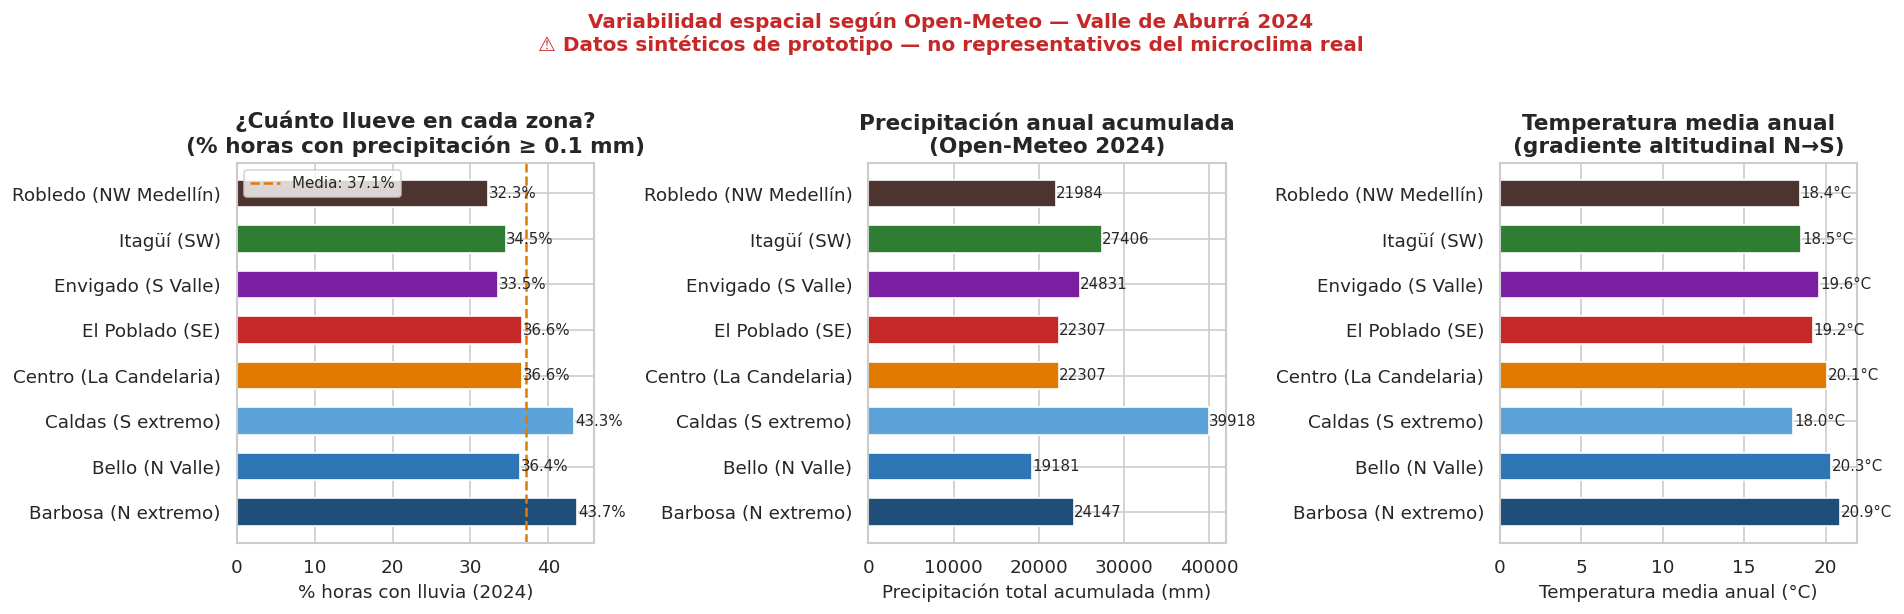

Figura guardada: fig1_variabilidad_espacial.png


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colores = [cfg['color'] for cfg in PUNTOS.values()]

# ── Panel 1: % horas con lluvia por punto ─────────────────────────────────
ax = axes[0]
bars = ax.barh(resumen['punto'], resumen['pct_lluvia'], color=colores, edgecolor='white', height=0.6)
ax.set_xlabel('% horas con lluvia (2024)')
ax.set_title('¿Cuánto llueve en cada zona?\n(% horas con precipitación ≥ 0.1 mm)', fontweight='bold')
ax.axvline(resumen['pct_lluvia'].mean(), color=COLORS['accent'], linestyle='--', linewidth=1.5, label=f"Media: {resumen['pct_lluvia'].mean():.1f}%")
ax.legend(fontsize=9)
for bar, val in zip(bars, resumen['pct_lluvia']):
    ax.text(val + 0.1, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontsize=9)

# ── Panel 2: Precipitación total anual ───────────────────────────────────
ax = axes[1]
bars = ax.barh(resumen['punto'], resumen['precip_total_mm'], color=colores, edgecolor='white', height=0.6)
ax.set_xlabel('Precipitación total acumulada (mm)')
ax.set_title('Precipitación anual acumulada\n(Open-Meteo 2024)', fontweight='bold')
for bar, val in zip(bars, resumen['precip_total_mm']):
    ax.text(val + 1, bar.get_y() + bar.get_height()/2, f'{val:.0f}', va='center', fontsize=9)

# ── Panel 3: Temperatura media ────────────────────────────────────────────
ax = axes[2]
bars = ax.barh(resumen['punto'], resumen['temp_media_c'], color=colores, edgecolor='white', height=0.6)
ax.set_xlabel('Temperatura media anual (°C)')
ax.set_title('Temperatura media anual\n(gradiente altitudinal N→S)', fontweight='bold')
for bar, val in zip(bars, resumen['temp_media_c']):
    ax.text(val + 0.05, bar.get_y() + bar.get_height()/2, f'{val:.1f}°C', va='center', fontsize=9)

fig.suptitle(
    f'Variabilidad espacial según Open-Meteo — Valle de Aburrá 2024\n'
    f'⚠️ Datos sintéticos de prototipo — no representativos del microclima real',
    fontsize=12, fontweight='bold', color=COLORS['warn'], y=1.02
)
plt.tight_layout()
plt.savefig('fig1_variabilidad_espacial.png', bbox_inches='tight')
plt.show()
print('Figura guardada: fig1_variabilidad_espacial.png')

## 5. Estacionalidad — Ciclo anual de precipitación

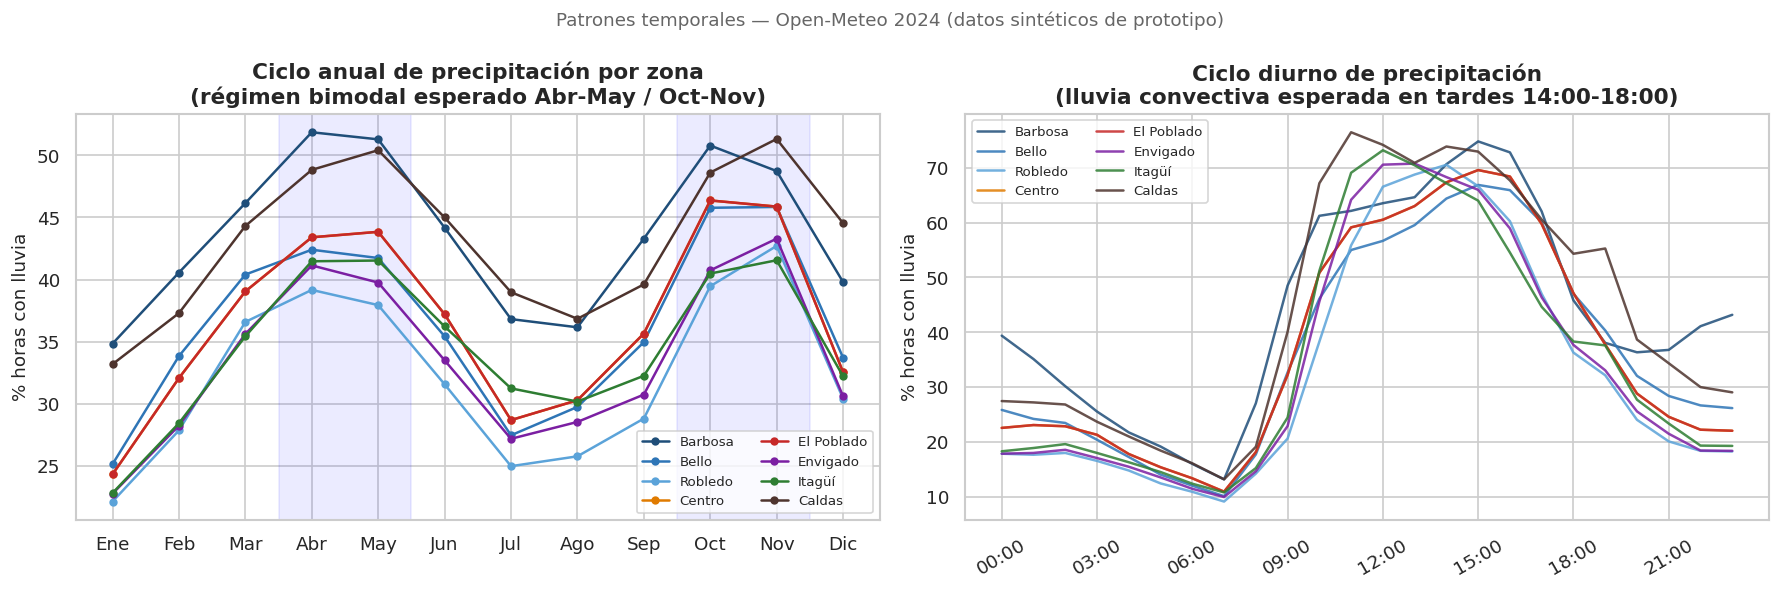

Figura guardada: fig2_estacionalidad.png


In [21]:
# Medellín tiene régimen bimodal: lluvias en abril-mayo y octubre-noviembre
df_all['mes'] = df_all['time'].dt.month
df_all['hora'] = df_all['time'].dt.hour

lluvia_mensual = df_all.groupby(['mes', 'punto'])['llueve'].mean().reset_index()
lluvia_mensual['pct_lluvia'] = lluvia_mensual['llueve'] * 100

meses_labels = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ── Panel 1: Ciclo anual por punto ────────────────────────────────────────
ax = axes[0]
for nombre, cfg in PUNTOS.items():
    datos = lluvia_mensual[lluvia_mensual['punto'] == nombre]
    ax.plot(datos['mes'], datos['pct_lluvia'], marker='o', markersize=4,
            color=cfg['color'], label=nombre.split('(')[0].strip(), linewidth=1.5)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(meses_labels)
ax.set_ylabel('% horas con lluvia')
ax.set_title('Ciclo anual de precipitación por zona\n(régimen bimodal esperado Abr-May / Oct-Nov)', fontweight='bold')
ax.legend(fontsize=8, ncol=2)
ax.axvspan(3.5, 5.5, alpha=0.08, color='blue', label='1ª temporada')
ax.axvspan(9.5, 11.5, alpha=0.08, color='blue')

# ── Panel 2: Ciclo diurno (hora del día) ──────────────────────────────────
lluvia_diurna = df_all.groupby(['hora', 'punto'])['llueve'].mean().reset_index()
lluvia_diurna['pct_lluvia'] = lluvia_diurna['llueve'] * 100

ax = axes[1]
for nombre, cfg in PUNTOS.items():
    datos = lluvia_diurna[lluvia_diurna['punto'] == nombre]
    ax.plot(datos['hora'], datos['pct_lluvia'], color=cfg['color'],
            label=nombre.split('(')[0].strip(), linewidth=1.5, alpha=0.85)

ax.set_xticks(range(0, 24, 3))
ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 24, 3)], rotation=30)
ax.set_ylabel('% horas con lluvia')
ax.set_title('Ciclo diurno de precipitación\n(lluvia convectiva esperada en tardes 14:00-18:00)', fontweight='bold')
ax.legend(fontsize=8, ncol=2)

fig.suptitle('Patrones temporales — Open-Meteo 2024 (datos sintéticos de prototipo)',
             fontsize=11, color=COLORS['neutral'])
plt.tight_layout()
plt.savefig('fig2_estacionalidad.png', bbox_inches='tight')
plt.show()
print('Figura guardada: fig2_estacionalidad.png')

## 6. Análisis de correlación entre puntos

**Hipótesis central:** Si Open-Meteo tiene resolución ~25 km, los puntos dentro del Valle de Aburrá (~40 km de largo) deberían tener precipitaciones altamente correlacionadas entre sí. Esto confirmaría que el modelo global no diferencia el microclima local.

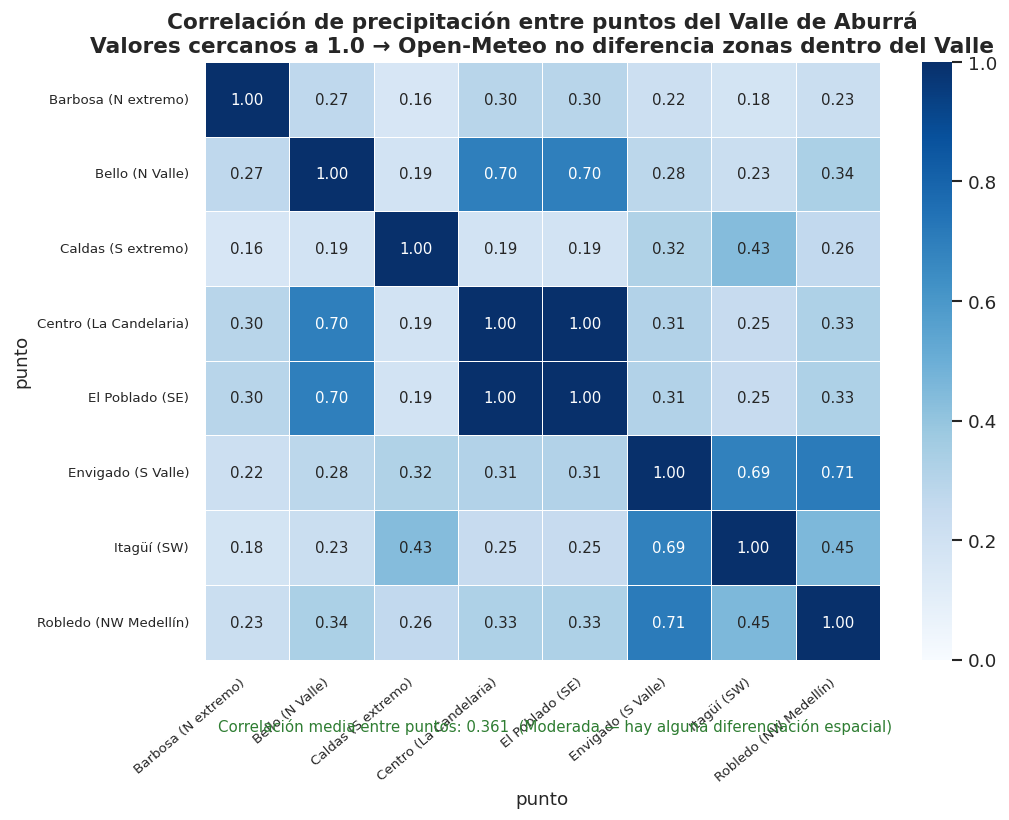

Correlación media inter-puntos: 0.361
Figura guardada: fig3_correlacion_espacial.png


In [22]:
# Pivot: una columna por punto, filas = horas
# Usar solo el punto Centro como referencia temporal
df_pivot = df_all.pivot_table(index='time', columns='punto', values='precipitacion_mm')
corr_matrix = df_pivot.corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    annot=True, fmt='.2f', cmap='Blues',
    vmin=0, vmax=1,
    linewidths=0.5, linecolor='white',
    annot_kws={'size': 9},
    ax=ax
)

ax.set_title(
    'Correlación de precipitación entre puntos del Valle de Aburrá\n'
    'Valores cercanos a 1.0 → Open-Meteo no diferencia zonas dentro del Valle',
    fontweight='bold'
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right', fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)

# Correlación media (excluyendo diagonal)
corr_vals = corr_matrix.values
np.fill_diagonal(corr_vals, np.nan)
corr_media = np.nanmean(corr_vals)

ax.text(0.02, -0.12,
    f'Correlación media entre puntos: {corr_media:.3f}  '
    f'({"Alta — Open-Meteo homogeneiza el Valle" if corr_media > 0.8 else "Moderada — hay alguna diferenciación espacial"})',
    transform=ax.transAxes, fontsize=9,
    color=COLORS['warn'] if corr_media > 0.8 else COLORS['ok']
)

plt.tight_layout()
plt.savefig('fig3_correlacion_espacial.png', bbox_inches='tight')
plt.show()
print(f'Correlación media inter-puntos: {corr_media:.3f}')
print('Figura guardada: fig3_correlacion_espacial.png')

## 7. Modelo base de predicción — prototipo técnico

> ⚠️ Este modelo se entrena con datos de Open-Meteo y se evalúa contra el mismo Open-Meteo.  
> Es una **validación técnica del pipeline**, no una medición real de utilidad para Medellín.  
> El modelo definitivo se entrenará con datos del SIATA.

In [23]:
# Usar datos del punto Centro como representativo para el modelo base
df_modelo = df_all[df_all['punto'] == 'Centro (La Candelaria)'].copy()
df_modelo = df_modelo.dropna(subset=['precipitacion_mm','temperatura_c',
                                      'humedad_relativa_pct','cobertura_nubosa_pct',
                                      'velocidad_viento_ms'])

# Features e ingeniería básica
df_modelo['hora_sin'] = np.sin(2 * np.pi * df_modelo['hora'] / 24)
df_modelo['hora_cos'] = np.cos(2 * np.pi * df_modelo['hora'] / 24)
df_modelo['mes_sin']  = np.sin(2 * np.pi * df_modelo['mes'] / 12)
df_modelo['mes_cos']  = np.cos(2 * np.pi * df_modelo['mes'] / 12)

FEATURES = [
    'temperatura_c', 'humedad_relativa_pct', 'cobertura_nubosa_pct',
    'velocidad_viento_ms', 'hora_sin', 'hora_cos', 'mes_sin', 'mes_cos'
]
TARGET = 'llueve'

X = df_modelo[FEATURES]
y = df_modelo[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {len(X_train):,} registros | Test: {len(X_test):,} registros')
print(f'Balance clases en test — llueve: {y_test.mean()*100:.1f}% | no llueve: {(1-y_test.mean())*100:.1f}%')

Train: 70,137 registros | Test: 17,535 registros
Balance clases en test — llueve: 36.6% | no llueve: 63.4%


In [24]:
# ── Entrenamiento ─────────────────────────────────────────────────────────
modelos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
}

resultados = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]
    resultados[nombre] = {
        'modelo':    modelo,
        'y_pred':    y_pred,
        'y_prob':    y_prob,
        'accuracy':  accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall':    recall_score(y_test, y_pred),
        'f1':        f1_score(y_test, y_pred),
        'roc_auc':   roc_auc_score(y_test, y_prob),
    }

# ── Benchmark: Open-Meteo "forecast" simulado ─────────────────────────────
# Simula el benchmark usando precipitacion_mm del mismo dataset como predicción
# En producción: comparar contra el endpoint /forecast de Open-Meteo
benchmark_pred = (df_modelo.loc[y_test.index, 'precipitacion_mm'] >= LLUVIA_UMBRAL_MM).astype(int)
resultados['Open-Meteo (benchmark)'] = {
    'accuracy':  accuracy_score(y_test, benchmark_pred),
    'precision': precision_score(y_test, benchmark_pred),
    'recall':    recall_score(y_test, benchmark_pred),
    'f1':        f1_score(y_test, benchmark_pred),
    'roc_auc':   None,
}

# ── Tabla de métricas ─────────────────────────────────────────────────────
print('=== MÉTRICAS DE EVALUACIÓN — PROTOTIPO TÉCNICO ===')
print(f'{"Modelo":<30} {"Accuracy":>10} {"Precision":>10} {"Recall":>10} {"F1":>10} {"ROC-AUC":>10}')
print('-' * 82)
for nombre, r in resultados.items():
    roc = f"{r['roc_auc']:.4f}" if r['roc_auc'] else '   N/A'
    print(f"{nombre:<30} {r['accuracy']:>10.4f} {r['precision']:>10.4f} {r['recall']:>10.4f} {r['f1']:>10.4f} {roc:>10}")

print()
for nombre in ['Regresión Logística', 'Random Forest']:
    delta_f1 = resultados[nombre]['f1'] - resultados['Open-Meteo (benchmark)']['f1']
    estado = '✅ KR2 cumplido' if delta_f1 >= 0.02 else '⚠️  KR2 no alcanzado aún'
    print(f'{nombre} vs benchmark → ΔF1 = {delta_f1:+.4f}  [{estado}]')

print()
print('⚠️  NOTA: Benchmark simulado con misma fuente → sesgo optimista esperado.')
print('   Validar con datos reales del SIATA cuando estén disponibles.')

=== MÉTRICAS DE EVALUACIÓN — PROTOTIPO TÉCNICO ===
Modelo                           Accuracy  Precision     Recall         F1    ROC-AUC
----------------------------------------------------------------------------------
Regresión Logística                0.7341     0.6247     0.6847     0.6533     0.7825
Random Forest                      0.7674     0.7149     0.6062     0.6561     0.8219
Open-Meteo (benchmark)             1.0000     1.0000     1.0000     1.0000        N/A

Regresión Logística vs benchmark → ΔF1 = -0.3467  [⚠️  KR2 no alcanzado aún]
Random Forest vs benchmark → ΔF1 = -0.3439  [⚠️  KR2 no alcanzado aún]

⚠️  NOTA: Benchmark simulado con misma fuente → sesgo optimista esperado.
   Validar con datos reales del SIATA cuando estén disponibles.


## 8. Visualización de métricas y matriz de confusión

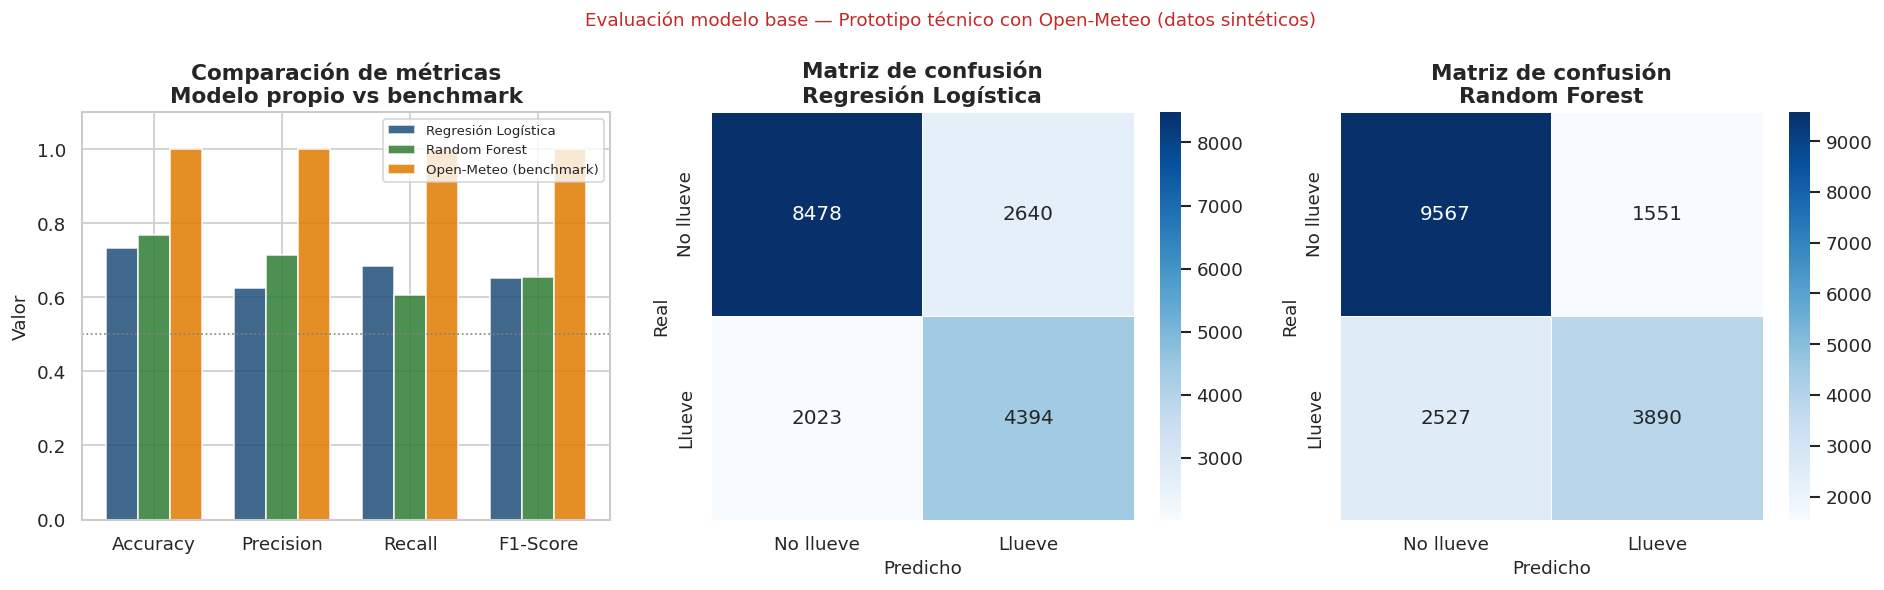

Figura guardada: fig4_metricas_modelo.png


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── Panel 1: Comparación de métricas ─────────────────────────────────────
ax = axes[0]
metricas_nombres = ['accuracy', 'precision', 'recall', 'f1']
metricas_labels  = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metricas_labels))
width = 0.25

colores_modelos = [COLORS['primary'], COLORS['ok'], COLORS['accent']]
for i, (nombre, r) in enumerate(resultados.items()):
    vals = [r[m] for m in metricas_nombres]
    bars = ax.bar(x + i * width, vals, width, label=nombre, color=colores_modelos[i], alpha=0.85)

ax.set_xticks(x + width)
ax.set_xticklabels(metricas_labels)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Valor')
ax.set_title('Comparación de métricas\nModelo propio vs benchmark', fontweight='bold')
ax.legend(fontsize=8)
ax.axhline(0.5, color='gray', linestyle=':', linewidth=1)

# ── Paneles 2 y 3: Matrices de confusión ─────────────────────────────────
for idx, nombre_modelo in enumerate(['Regresión Logística', 'Random Forest']):
    ax = axes[idx + 1]
    cm = confusion_matrix(y_test, resultados[nombre_modelo]['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No llueve', 'Llueve'],
                yticklabels=['No llueve', 'Llueve'],
                linewidths=0.5, linecolor='white')
    ax.set_title(f'Matriz de confusión\n{nombre_modelo}', fontweight='bold')
    ax.set_ylabel('Real')
    ax.set_xlabel('Predicho')

fig.suptitle(
    'Evaluación modelo base — Prototipo técnico con Open-Meteo (datos sintéticos)',
    fontsize=11, color=COLORS['warn']
)
plt.tight_layout()
plt.savefig('fig4_metricas_modelo.png', bbox_inches='tight')
plt.show()
print('Figura guardada: fig4_metricas_modelo.png')

## 9. Importancia de variables (Random Forest)

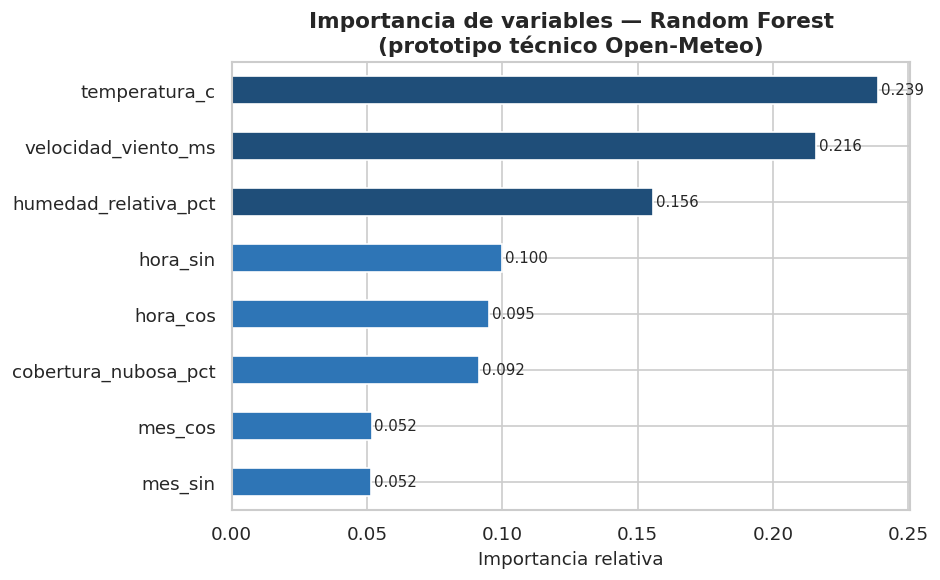

Figura guardada: fig5_importancia_variables.png


In [26]:
rf = resultados['Random Forest']['modelo']
importancias = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
colores_imp = [COLORS['secondary'] if v < importancias.max() * 0.5 else COLORS['primary']
               for v in importancias.values]
importancias.plot(kind='barh', ax=ax, color=colores_imp, edgecolor='white')
ax.set_title('Importancia de variables — Random Forest\n(prototipo técnico Open-Meteo)', fontweight='bold')
ax.set_xlabel('Importancia relativa')
for i, (idx, val) in enumerate(importancias.items()):
    ax.text(val + 0.001, i, f'{val:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('fig5_importancia_variables.png', bbox_inches='tight')
plt.show()
print('Figura guardada: fig5_importancia_variables.png')

## 10. Conclusiones y estado del KR2

In [27]:
print('=' * 65)
print('CONCLUSIONES DEL ANÁLISIS — SPRINT 2')
print('=' * 65)

print()
print('1. VARIABILIDAD ESPACIAL DE OPEN-METEO')
rango = resumen['pct_lluvia'].max() - resumen['pct_lluvia'].min()
print(f'   Rango de % lluvia entre los {len(PUNTOS)} puntos: {rango:.1f} pp')
if rango < 3:
    print('   → Open-Meteo prácticamente no diferencia zonas dentro del Valle.')
    print('     Esto confirma la necesidad de datos locales del SIATA.')
else:
    print('   → Open-Meteo muestra alguna diferenciación espacial.')
    print('     Los datos del SIATA seguirán siendo superiores a resolución local.')

print()
print('2. ESTADO DEL KR2 (fase prototipo)')
for nombre in ['Regresión Logística', 'Random Forest']:
    delta = resultados[nombre]['f1'] - resultados['Open-Meteo (benchmark)']['f1']
    print(f'   {nombre}: ΔF1 = {delta:+.4f}')
print('   ⚠️  Benchmark simulado con la misma fuente → no válido para cumplimiento real del KR2.')
print('   El KR2 se medirá formalmente con datos del SIATA como ground truth.')

print()
print('3. PIPELINE TÉCNICO')
print('   ✅ Descarga de datos: funcional')
print('   ✅ Esquema canónico: implementado (campo es_sintetico)')
print('   ✅ Binarización con umbral OMM (≥ 0.1 mm): funcional')
print('   ✅ Ingeniería de features temporales: funcional')
print('   ✅ Entrenamiento Logistic Regression + Random Forest: funcional')
print('   ✅ Métricas (Accuracy, Precision, Recall, F1, ROC-AUC): funcional')
print('   ⏳ Ground truth real (SIATA): pendiente de datos')

print()
print('4. PRÓXIMO PASO')
print('   Al recibir datos del SIATA:')
print('   - Reemplazar fuente en descargar_punto() por ingesta SIATA')
print('   - Mantener es_sintetico=False para registros reales')
print('   - Reejecutar desde sección 3 para obtener métricas definitivas')
print('=' * 65)

CONCLUSIONES DEL ANÁLISIS — SPRINT 2

1. VARIABILIDAD ESPACIAL DE OPEN-METEO
   Rango de % lluvia entre los 8 puntos: 11.4 pp
   → Open-Meteo muestra alguna diferenciación espacial.
     Los datos del SIATA seguirán siendo superiores a resolución local.

2. ESTADO DEL KR2 (fase prototipo)
   Regresión Logística: ΔF1 = -0.3467
   Random Forest: ΔF1 = -0.3439
   ⚠️  Benchmark simulado con la misma fuente → no válido para cumplimiento real del KR2.
   El KR2 se medirá formalmente con datos del SIATA como ground truth.

3. PIPELINE TÉCNICO
   ✅ Descarga de datos: funcional
   ✅ Esquema canónico: implementado (campo es_sintetico)
   ✅ Binarización con umbral OMM (≥ 0.1 mm): funcional
   ✅ Ingeniería de features temporales: funcional
   ✅ Entrenamiento Logistic Regression + Random Forest: funcional
   ✅ Métricas (Accuracy, Precision, Recall, F1, ROC-AUC): funcional
   ⏳ Ground truth real (SIATA): pendiente de datos

4. PRÓXIMO PASO
   Al recibir datos del SIATA:
   - Reemplazar fuente en des

In [28]:
from pathlib import Path
import re
import joblib

output_dir = Path("../models")
output_dir.mkdir(parents=True, exist_ok=True)

saved_files = []
for nombre_modelo, modelo_entrenado in modelos.items():
    nombre_archivo = re.sub(r"[^a-z0-9]+", "_", nombre_modelo.lower()).strip("_")
    ruta_salida = output_dir / f"{nombre_archivo}.pkl"
    joblib.dump(modelo_entrenado, ruta_salida)
    saved_files.append(str(ruta_salida.resolve()))

print("Modelos exportados a .pkl:")
for ruta in saved_files:
    print(f"- {ruta}")
print(f"Total exportados: {len(saved_files)}")

Modelos exportados a .pkl:
- C:\Users\LENOVO\Desktop\Monitoreo-de-variables-ambientales\Data-science\models\regresi_n_log_stica.pkl
- C:\Users\LENOVO\Desktop\Monitoreo-de-variables-ambientales\Data-science\models\random_forest.pkl
Total exportados: 2
